<a href="https://colab.research.google.com/github/mohiuddin2806-lang/machine-learning-/blob/main/CN7031_week_5_u2975262.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# @title ▶ 1.1 Install Java 17 and Apache Spark (PySpark 4.0.4)
# Import the tools used to run installation commands and check the result.
import os
import subprocess
import sys
from pathlib import Path

# Spark runs on the Java Virtual Machine; Spark 4 needs Java 17 or newer.
SPARK_VERSION = '4.0.4'
JAVA = Path('/usr/lib/jvm/java-17-openjdk-amd64')

# Run a system command and stop with a useful error if it fails.
def checked(args, timeout=900):
    p = subprocess.run(args, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, timeout=timeout)
    if p.returncode:
        raise RuntimeError(p.stdout[-5000:])
    return p.stdout

# Install Java 17 only when it is not already on this VM.
if not (JAVA / 'bin/java').exists():
    print('Installing Java 17 …')
    checked(['apt-get', 'update', '-qq'])
    checked(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jdk-headless'])

# Point Spark at Java 17.
os.environ['JAVA_HOME'] = str(JAVA)
os.environ['PATH'] = f'{JAVA}/bin:' + os.environ['PATH']

# Install the PySpark package (Spark itself is bundled inside it), only if this version is missing.
from importlib.metadata import version, PackageNotFoundError
try:
    installed = version('pyspark')
except PackageNotFoundError:
    installed = None
if installed != SPARK_VERSION:
    print(f'Installing PySpark {SPARK_VERSION} (about 450 MB) …')
    checked([sys.executable, '-m', 'pip', 'install', '-q', f'pyspark=={SPARK_VERSION}'])
    if 'pyspark' in sys.modules:
        print('An older PySpark was already loaded: choose Runtime → Restart session, then run this cell again.')

# Spark's own log messages (INFO and WARN) would fill the cell outputs: show only errors.
SPARK_CONF = Path('/content/spark-conf')
SPARK_CONF.mkdir(parents=True, exist_ok=True)
(SPARK_CONF / 'log4j2.properties').write_text(
    'rootLogger.level = error\n'
    'rootLogger.appenderRef.stdout.ref = console\n'
    'appender.console.type = Console\n'
    'appender.console.name = console\n'
    'appender.console.target = SYSTEM_ERR\n'
    'appender.console.layout.type = PatternLayout\n'
    'appender.console.layout.pattern = %p %c{1}: %m%n\n'
    'logger.repl.name = org.apache.spark.repl.Main\n'
    'logger.repl.level = error\n')
os.environ['SPARK_CONF_DIR'] = str(SPARK_CONF)

# Java's start-up notices go to a log file instead of the notebook (Spark errors still appear in Python).
import pyspark.java_gateway as java_gateway
if not getattr(java_gateway.Popen, 'quiet', False):
    start_java = java_gateway.Popen
    def quiet_popen(command, **kwargs):
        kwargs.setdefault('stderr', open(SPARK_CONF / 'java.log', 'ab'))
        return start_java(command, **kwargs)
    quiet_popen.quiet = True
    java_gateway.Popen = quiet_popen

# When a query has a mistake, show only Python's short error message, not an extra JSON log of it.
from pyspark.logger import PySparkLogger
for name in ('SQLQueryContextLogger', 'DataFrameQueryContextLogger'):
    PySparkLogger.getLogger(name).disabled = True

# Show what was installed.
java_version = checked([str(JAVA / 'bin/java'), '-version']).splitlines()[0]
print(java_version)
print(f'PySpark {SPARK_VERSION} is installed ✓  Java 17 is ready ✓')

# Unzip the workspace files containing CompleteDataset.csv
print('Unzipping dataset files...')
import zipfile
with zipfile.ZipFile('/content/Working with SparkSQL-20261104 (2).zip', 'r') as zip_ref:
    zip_ref.extractall('/content')
print('Unzip complete.')

openjdk version "17.0.20.1" 2026-08-18
PySpark 4.0.4 is installed ✓  Java 17 is ready ✓
Unzipping dataset files...
Unzip complete.


In [6]:
# Check that the file is there, and its size (about 7.4 MB).
!ls -lh "/content/Working with SparkSQL-20261104/Sample Data/CompleteDataset.csv"

-rw-r--r-- 1 root root 7.4M Nov  4 18:09 '/content/Working with SparkSQL-20261104/Sample Data/CompleteDataset.csv'


In [9]:
!head -n 2 "/content/Working with SparkSQL-20261104/Sample Data/CompleteDataset.csv"

,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,Value,Wage,Special,Acceleration,Aggression,Agility,Balance,Ball control,Composure,Crossing,Curve,Dribbling,Finishing,Free kick accuracy,GK diving,GK handling,GK kicking,GK positioning,GK reflexes,Heading accuracy,Interceptions,Jumping,Long passing,Long shots,Marking,Penalties,Positioning,Reactions,Short passing,Shot power,Sliding tackle,Sprint speed,Stamina,Standing tackle,Strength,Vision,Volleys,CAM,CB,CDM,CF,CM,ID,LAM,LB,LCB,LCM,LDM,LF,LM,LS,LW,LWB,Preferred Positions,RAM,RB,RCB,RCM,RDM,RF,RM,RS,RW,RWB,ST
0,Cristiano Ronaldo,32,https://cdn.sofifa.org/48/18/players/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Real Madrid CF,https://cdn.sofifa.org/24/18/teams/243.png,€95.5M,€565K,2228,89,63,89,63,93,95,85,81,91,94,76,7,11,15,14,11,88,29,95,77,92,22,85,95,96,83,94,23,91,92,31,80,85,88,89.0,53.0,62.0,91.0,82.0,20801,89.0,61.0,53.0,82.0,62.0,91.0,89.0,92.0,91.0,66.0,ST LW ,89.0,61.0,53.0,82.0,62.0,91.0,89.0,

In [11]:
# Create the SparkSession, then show its version and where it runs.
from pyspark.sql import SparkSession
spark=SparkSession \
.builder \
.appName ("Python Spark SQL basic example") \
.master ("local[*]") \
.getOrCreate()
print("Spark", spark.version, ".master:", spark.sparkContext.master)

Spark 4.0.4 .master: local[*]


In [13]:
# Read the CSV file into a DataFrame, then show its first 5 rows.
fifa_df = spark.read.load("/content/Working with SparkSQL-20261104/Sample Data/CompleteDataset.csv", format="csv",
                        inferSchema=True, header=True)
fifa_df.show(5)

+---+-----------------+---+--------------------+-----------+--------------------+-------+---------+-------------------+--------------------+------+-----+-------+------------+----------+-------+-------+------------+---------+--------+-----+---------+---------+------------------+---------+-----------+----------+--------------+-----------+----------------+-------------+-------+------------+----------+-------+---------+-----------+---------+-------------+----------+--------------+------------+-------+---------------+--------+------+-------+----+----+----+----+----+------+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+
|_c0|             Name|Age|               Photo|Nationality|                Flag|Overall|Potential|               Club|           Club Logo| Value| Wage|Special|Acceleration|Aggression|Agility|Balance|Ball control|Composure|Crossing|Curve|Dribbling|Finishing|Free kick accuracy|GK diving|GK handling|

In [15]:
# Show the column names and the type Spark inferred for each.
fifa_df.printSchema()

root
 |-- _c0: integer (nullable = true)
 |-- Name: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Photo: string (nullable = true)
 |-- Nationality: string (nullable = true)
 |-- Flag: string (nullable = true)
 |-- Overall: integer (nullable = true)
 |-- Potential: integer (nullable = true)
 |-- Club: string (nullable = true)
 |-- Club Logo: string (nullable = true)
 |-- Value: string (nullable = true)
 |-- Wage: string (nullable = true)
 |-- Special: integer (nullable = true)
 |-- Acceleration: string (nullable = true)
 |-- Aggression: string (nullable = true)
 |-- Agility: string (nullable = true)
 |-- Balance: string (nullable = true)
 |-- Ball control: string (nullable = true)
 |-- Composure: string (nullable = true)
 |-- Crossing: string (nullable = true)
 |-- Curve: string (nullable = true)
 |-- Dribbling: string (nullable = true)
 |-- Finishing: string (nullable = true)
 |-- Free kick accuracy: string (nullable = true)
 |-- GK diving: string (nullable = true)


In [16]:
# List the column names.
fifa_df.columns

['_c0',
 'Name',
 'Age',
 'Photo',
 'Nationality',
 'Flag',
 'Overall',
 'Potential',
 'Club',
 'Club Logo',
 'Value',
 'Wage',
 'Special',
 'Acceleration',
 'Aggression',
 'Agility',
 'Balance',
 'Ball control',
 'Composure',
 'Crossing',
 'Curve',
 'Dribbling',
 'Finishing',
 'Free kick accuracy',
 'GK diving',
 'GK handling',
 'GK kicking',
 'GK positioning',
 'GK reflexes',
 'Heading accuracy',
 'Interceptions',
 'Jumping',
 'Long passing',
 'Long shots',
 'Marking',
 'Penalties',
 'Positioning',
 'Reactions',
 'Short passing',
 'Shot power',
 'Sliding tackle',
 'Sprint speed',
 'Stamina',
 'Standing tackle',
 'Strength',
 'Vision',
 'Volleys',
 'CAM',
 'CB',
 'CDM',
 'CF',
 'CM',
 'ID',
 'LAM',
 'LB',
 'LCB',
 'LCM',
 'LDM',
 'LF',
 'LM',
 'LS',
 'LW',
 'LWB',
 'Preferred Positions',
 'RAM',
 'RB',
 'RCB',
 'RCM',
 'RDM',
 'RF',
 'RM',
 'RS',
 'RW',
 'RWB',
 'ST']

In [17]:
# Count the players (rows).
fifa_df.count()

17981

In [18]:
# Count the columns.
len(fifa_df.columns)

75

In [19]:
# Show the name, nationality and club of each player.
fifa_df.select('Name', 'Nationality', 'Club').show()


+-----------------+-----------+-------------------+
|             Name|Nationality|               Club|
+-----------------+-----------+-------------------+
|Cristiano Ronaldo|   Portugal|     Real Madrid CF|
|         L. Messi|  Argentina|       FC Barcelona|
|           Neymar|     Brazil|Paris Saint-Germain|
|        L. Suárez|    Uruguay|       FC Barcelona|
|         M. Neuer|    Germany|   FC Bayern Munich|
|   R. Lewandowski|     Poland|   FC Bayern Munich|
|           De Gea|      Spain|  Manchester United|
|        E. Hazard|    Belgium|            Chelsea|
|         T. Kroos|    Germany|     Real Madrid CF|
|       G. Higuaín|  Argentina|           Juventus|
|     Sergio Ramos|      Spain|     Real Madrid CF|
|     K. De Bruyne|    Belgium|    Manchester City|
|      T. Courtois|    Belgium|            Chelsea|
|       A. Sánchez|      Chile|            Arsenal|
|        L. Modrić|    Croatia|     Real Madrid CF|
|          G. Bale|      Wales|     Real Madrid CF|
|        S. 

In [20]:
# Show each different (name, long shots) pair once.
fifa_df.select('Name', 'Long shots').distinct().show()

+-----------------+----------+
|             Name|Long shots|
+-----------------+----------+
|Cristiano Ronaldo|        92|
|      J. Cuadrado|        80|
|      M. Brozović|        79|
|          A. Rami|        58|
|       D. Abraham|        65|
|     Borja Bastón|        73|
|       J. Montero|        68|
|      T. Barnetta|        74|
|          Wallace|        26|
|       A. Barreca|        42|
|    Y. Benalouane|        39|
|          Juankar|        64|
|        D. Appiah|        38|
|   Rafael Martins|        69|
|          Granell|        77|
|     A. Cornelius|        68|
|         J. Henry|        75|
|        M. Ozdoev|        69|
|            Fábio|        58|
|       T. Dingomé|        60|
+-----------------+----------+
only showing top 20 rows


In [21]:
# Show the players older than 21.
fifa_df.filter(fifa_df['Age'] > 21).select('Name', 'Age', 'Club') .show()

+-----------------+---+-------------------+
|             Name|Age|               Club|
+-----------------+---+-------------------+
|Cristiano Ronaldo| 32|     Real Madrid CF|
|         L. Messi| 30|       FC Barcelona|
|           Neymar| 25|Paris Saint-Germain|
|        L. Suárez| 30|       FC Barcelona|
|         M. Neuer| 31|   FC Bayern Munich|
|   R. Lewandowski| 28|   FC Bayern Munich|
|           De Gea| 26|  Manchester United|
|        E. Hazard| 26|            Chelsea|
|         T. Kroos| 27|     Real Madrid CF|
|       G. Higuaín| 29|           Juventus|
|     Sergio Ramos| 31|     Real Madrid CF|
|     K. De Bruyne| 26|    Manchester City|
|      T. Courtois| 25|            Chelsea|
|       A. Sánchez| 28|            Arsenal|
|        L. Modrić| 31|     Real Madrid CF|
|          G. Bale| 27|     Real Madrid CF|
|        S. Agüero| 29|    Manchester City|
|     G. Chiellini| 32|           Juventus|
|        G. Buffon| 39|           Juventus|
|        P. Dybala| 23|         

In [22]:
# Count the players older than 21.
fifa_df.filter(fifa_df['Age'] > 21).count()


13438

In [23]:
# Count the players of each age.
fifa_df.groupBy('Age').count().show()

+---+-----+
|Age|count|
+---+-----+
| 31|  671|
| 34|  272|
| 28| 1051|
| 26| 1202|
| 27| 1152|
| 44|    2|
| 22| 1324|
| 16|   13|
| 20| 1245|
| 40|    8|
| 19| 1069|
| 41|    3|
| 37|   69|
| 17|  258|
| 35|  191|
| 39|   20|
| 23| 1394|
| 38|   36|
| 25| 1522|
| 24| 1334|
+---+-----+
only showing top 20 rows


In [25]:
# Count the players of each age, sorted by age.
fifa_df.groupBy('Age').count().orderBy('Age').show()

+---+-----+
|Age|count|
+---+-----+
| 16|   13|
| 17|  258|
| 18|  672|
| 19| 1069|
| 20| 1245|
| 21| 1286|
| 22| 1324|
| 23| 1394|
| 24| 1334|
| 25| 1522|
| 26| 1202|
| 27| 1152|
| 28| 1051|
| 29| 1121|
| 30|  804|
| 31|  671|
| 32|  506|
| 33|  617|
| 34|  272|
| 35|  191|
+---+-----+
only showing top 20 rows


In [27]:
# Average overall rating and number of players per nationality, best first.
from pyspark.sql import functions as F
fifa_df.groupBy("Nationality") \
.agg(F.round(F.avg("Overall"), 1).alias("avg_Overall"), F.count("*").alias("players")) \
.filter(F.col("players") >= 200) \
.orderBy(F.desc("avg_Overall")) \
.show(10)

+-----------+-----------+-------+
|Nationality|avg_Overall|players|
+-----------+-----------+-------+
|      Chile|       70.9|    375|
|     Brazil|       70.9|    812|
|   Portugal|       70.6|    367|
|      Spain|       69.9|   1019|
|    Belgium|       68.1|    272|
|Netherlands|       68.1|    429|
|  Argentina|       67.8|    965|
|     France|       67.3|    978|
|     Turkey|       67.2|    291|
|      Italy|       67.0|    799|
+-----------+-----------+-------+
only showing top 10 rows


In [28]:
# Add a numeric value column in millions of euros, then list the most valuable players.
number = F.expr("try_cast(regexp_extract(value,'([0-9.]+)',1)AS DOUBLE)")
fifa_df = fifa_df.withColumn("value_m",F.when(F.col("value").endswith("K"),number/1000).otherwise(number))
fifa_df.select("Name", "Club", "value_m").orderBy(F.desc("value_m")).show(10)

+-----------------+-------------------+-------+
|             Name|               Club|value_m|
+-----------------+-------------------+-------+
|           Neymar|Paris Saint-Germain|  123.0|
|         L. Messi|       FC Barcelona|  105.0|
|        L. Suárez|       FC Barcelona|   97.0|
|Cristiano Ronaldo|     Real Madrid CF|   95.5|
|   R. Lewandowski|   FC Bayern Munich|   92.0|
|        E. Hazard|            Chelsea|   90.5|
|     K. De Bruyne|    Manchester City|   83.0|
|         T. Kroos|     Real Madrid CF|   79.0|
|        P. Dybala|           Juventus|   79.0|
|       G. Higuaín|           Juventus|   77.0|
+-----------------+-------------------+-------+
only showing top 10 rows


In [29]:
# Summary statistics of age, overall rating and value.
fifa_df.describe("Age", "Overall", "value_m").show()

+-------+------------------+-----------------+------------------+
|summary|               Age|          Overall|           value_m|
+-------+------------------+-----------------+------------------+
|  count|             17981|            17981|             17981|
|   mean|25.144541460430453|66.24798398309326|2.3853895778877434|
| stddev| 4.614272345005113|6.987965339747426| 5.353969970368187|
|    min|                16|               46|               0.0|
|    max|                47|               94|             123.0|
+-------+------------------+-----------------+------------------+



In [30]:
# Define young players with high potential: no data is read yet.
young_stars = fifa_df.filter((F.col("Age")<21)&(F.col("Potential")>=85)) \
                     .select("Name", "Age","Club", "Overall", "Potential")\
                     .orderBy(F.desc("Potential"))

print(type(young_stars))

<class 'pyspark.sql.classic.dataframe.DataFrame'>


In [31]:
# Show the plan Spark has built for young_stars.
young_stars.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [Potential#24 DESC NULLS LAST], true, 0
   +- Exchange rangepartitioning(Potential#24 DESC NULLS LAST, 200), ENSURE_REQUIREMENTS, [plan_id=421]
      +- Project [Name#18, Age#19, Club#25, Overall#23, Potential#24]
         +- Filter (((isnotnull(Age#19) AND isnotnull(Potential#24)) AND (Age#19 < 21)) AND (Potential#24 >= 85))
            +- FileScan csv [Name#18,Age#19,Overall#23,Potential#24,Club#25] Batched: false, DataFilters: [isnotnull(Age#19), isnotnull(Potential#24), (Age#19 < 21), (Potential#24 >= 85)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/content/Working with SparkSQL-20261104/Sample Data/CompleteDatas..., PartitionFilters: [], PushedFilters: [IsNotNull(Age), IsNotNull(Potential), LessThan(Age,21), GreaterThanOrEqual(Potential,85)], ReadSchema: struct<Name:string,Age:int,Overall:int,Potential:int,Club:string>




In [32]:
# Run the plan with an action and show the result.
young_stars.show(10)


+-------------+---+-------------------+-------+---------+
|         Name|Age|               Club|Overall|Potential|
+-------------+---+-------------------+-------+---------+
|    K. Mbappé| 18|Paris Saint-Germain|     83|       94|
|G. Donnarumma| 18|              Milan|     82|       94|
|   O. Dembélé| 20|       FC Barcelona|     83|       92|
|Gabriel Jesus| 20|    Manchester City|     81|       92|
| Y. Tielemans| 20|          AS Monaco|     80|       90|
|     E. Barco| 18|      Independiente|     72|       90|
|     A. Gomes| 16|  Manchester United|     64|       90|
|  M. Rashford| 19|  Manchester United|     80|       89|
|   C. Pulisic| 18|  Borussia Dortmund|     78|       89|
|   C. Pulisic| 18|  Borussia Dortmund|     78|       89|
+-------------+---+-------------------+-------+---------+
only showing top 10 rows


In [33]:
# Count the rows, and the players left after removing duplicate IDs.
print("rows:", fifa_df.count(),".different players:", fifa_df.dropDuplicates(["ID"]).count())

rows: 17981 .different players: 17929


In [34]:
# Show how many partitions the DataFrame is split into.
fifa_df.rdd.getNumPartitions()

2

In [35]:
# Register the DataFrame as a SQL temporary view called FifaView, then list the views.
fifa_df.createOrReplaceTempView("FifaView")
spark.sql ("SHOW VIEWS").show()

+---------+--------+-----------+
|namespace|viewName|isTemporary|
+---------+--------+-----------+
|         |fifaview|       true|
+---------+--------+-----------+



In [36]:
# Retrieve the content of the dataset.
sqlDF = spark.sql("SELECT * FROM FifaView")
sqlDF.show(5)

+---+-----------------+---+--------------------+-----------+--------------------+-------+---------+-------------------+--------------------+------+-----+-------+------------+----------+-------+-------+------------+---------+--------+-----+---------+---------+------------------+---------+-----------+----------+--------------+-----------+----------------+-------------+-------+------------+----------+-------+---------+-----------+---------+-------------+----------+--------------+------------+-------+---------------+--------+------+-------+----+----+----+----+----+------+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+-------+
|_c0|             Name|Age|               Photo|Nationality|                Flag|Overall|Potential|               Club|           Club Logo| Value| Wage|Special|Acceleration|Aggression|Agility|Balance|Ball control|Composure|Crossing|Curve|Dribbling|Finishing|Free kick accuracy|GK diving|GK h

In [37]:
# Count the players by age.
sqlDF = spark.sql("SELECT Age, count(*) as count FROM FifaView GROUP BY Age")
sqlDF.show()

+---+-----+
|Age|count|
+---+-----+
| 31|  671|
| 34|  272|
| 28| 1051|
| 26| 1202|
| 27| 1152|
| 44|    2|
| 22| 1324|
| 16|   13|
| 20| 1245|
| 40|    8|
| 19| 1069|
| 41|    3|
| 37|   69|
| 17|  258|
| 35|  191|
| 39|   20|
| 23| 1394|
| 38|   36|
| 25| 1522|
| 24| 1334|
+---+-----+
only showing top 20 rows


In [39]:
# Import pandas, NumPy and Matplotlib for plotting.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
print("pandas", pd.__version__, "NumPy", np.__version__)

pandas 2.2.3 NumPy 2.4.6


In [41]:
# Convert the Spark result to a pandas DataFrame and show its first rows.
pandas_df = sqlDF.toPandas()
pandas_df.head()

,Age,count
0,31,671
1,34,272
2,28,1051
3,26,1202
4,27,1152


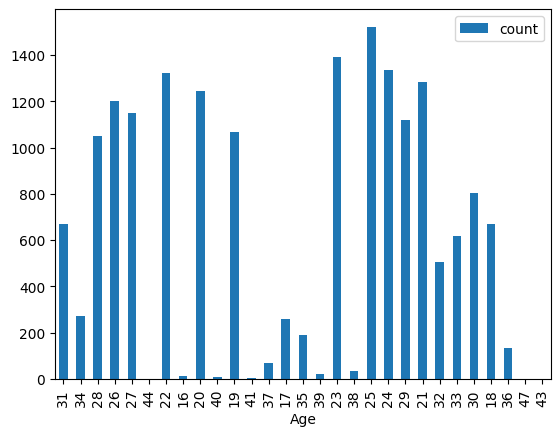

In [43]:
pandas_df.plot(x="Age", y="count", kind="bar")
plt.show()

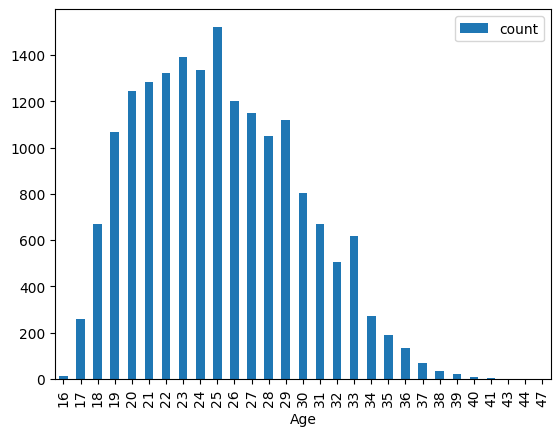

In [46]:
# Plot the same chart, sorted by age.
pandas_df.sort_values(by='Age', ascending=True).plot(x='Age', y='count', kind='bar')
plt.show()

In [47]:
# Count the players in each club.
sqlDF=spark.sql("SELECT Club, count(*) FROM FifaView GROUP BY Club")
sqlDF.show()

+--------------------+--------+
|                Club|count(1)|
+--------------------+--------+
|             Palermo|      28|
|         Yeovil Town|      21|
|  1. FC Union Berlin|      27|
|  Santiago Wanderers|      20|
|               Carpi|      30|
|Evkur Yeni Malaty...|      30|
|          Sagan Tosu|      25|
|            FC Basel|      25|
|  Argentinos Juniors|      28|
|       Karlsruher SC|      27|
|  Lorca Deportiva CF|      29|
|     SC Paderborn 07|      28|
|     Cheltenham Town|      28|
|San Lorenzo de Al...|      28|
|         SC Freiburg|      32|
|  SpVgg Unterhaching|      28|
|Atletico Nacional...|      28|
|Universidad Católica|      20|
|         GFC Ajaccio|      25|
|           FC Luzern|      27|
+--------------------+--------+
only showing top 20 rows


In [48]:
# Count the players in each club and keep the clubs with more than 33.
sqlDF=spark.sql("SELECT Club, count(*) FROM FifaView GROUP BY Club HAVING count(*)>33")
sqlDF.show()

+------------------+--------+
|              Club|count(1)|
+------------------+--------+
| Manchester United|      34|
|     UD Las Palmas|      34|
|              NULL|     248|
|Olympique Lyonnais|      34|
|     VfL Wolfsburg|      34|
|          OGC Nice|      34|
|     Villarreal CF|      35|
|         FC Nantes|      34|
| Borussia Dortmund|      34|
+------------------+--------+



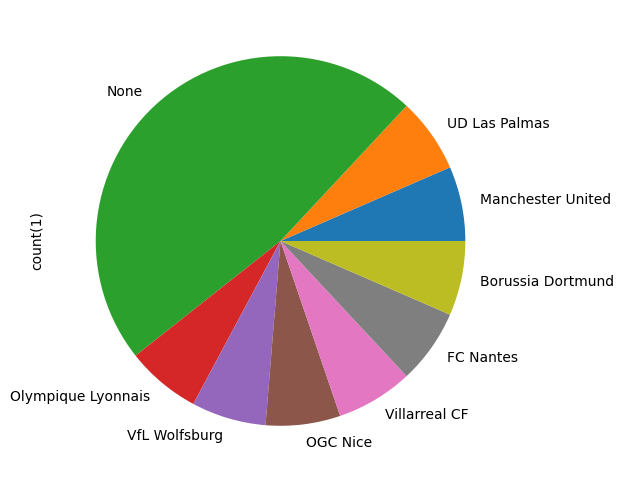

In [50]:
# Plot the clubs as a pie chart.
pandas_df=sqlDF.toPandas()
pandas_df.set_index('Club').plot(y='count(1)', kind='pie', legend=False, figsize=(6,6))
plt.show()

+------------------+-------+
|              Club|players|
+------------------+-------+
|     Villarreal CF|     35|
| Manchester United|     34|
|     UD Las Palmas|     34|
|Olympique Lyonnais|     34|
|     VfL Wolfsburg|     34|
|          OGC Nice|     34|
|         FC Nantes|     34|
| Borussia Dortmund|     34|
+------------------+-------+



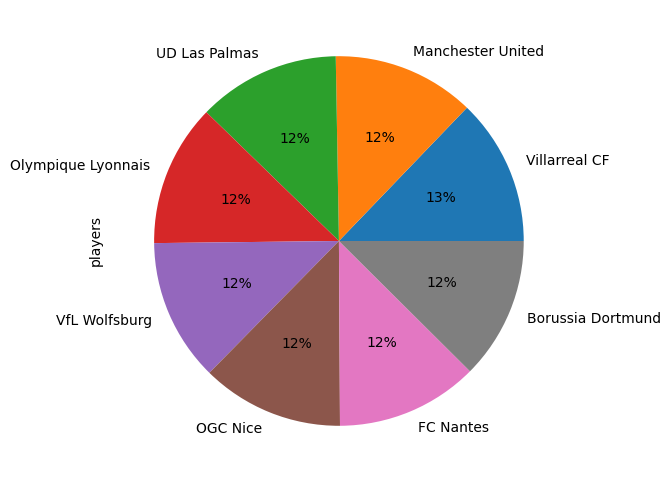

In [51]:
# Clubs with more than 33 players, without the players who have no club.
sqlDF=spark.sql("SELECT Club, count(*) AS players FROM FifaView WHERE Club IS NOT NULL GROUP BY Club HAVING count(*)>33 ORDER BY players DESC""")
sqlDF.show()
sqlDF.toPandas().set_index('Club').plot(y='players', kind='pie', legend=False, autopct='%1.0f%%', figsize=(6,6))
plt.show()

In [52]:
# The question in SQL: show the plan.
spark.sql("SELECT Club, avg(overall) AS avg_overall FROM FifaView GROUP BY Club").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[Club#25], functions=[avg(overall#23)])
   +- Exchange hashpartitioning(Club#25, 200), ENSURE_REQUIREMENTS, [plan_id=1022]
      +- HashAggregate(keys=[Club#25], functions=[partial_avg(overall#23)])
         +- FileScan csv [Overall#23,Club#25] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/content/Working with SparkSQL-20261104/Sample Data/CompleteDatas..., PartitionFilters: [], PushedFilters: [], ReadSchema: struct<Overall:int,Club:string>




In [53]:
# The same question with DataFrame operations: show the plan.
fifa_df.groupBy("Club").agg(F.avg("Overall").alias("avg_Overall")).explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[Club#25], functions=[avg(Overall#23)])
   +- Exchange hashpartitioning(Club#25, 200), ENSURE_REQUIREMENTS, [plan_id=1035]
      +- HashAggregate(keys=[Club#25], functions=[partial_avg(Overall#23)])
         +- FileScan csv [Overall#23,Club#25] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/content/Working with SparkSQL-20261104/Sample Data/CompleteDatas..., PartitionFilters: [], PushedFilters: [], ReadSchema: struct<Overall:int,Club:string>




In [54]:
# Example: the 10 best players in Manchester United.
spark.sql("""
    SELECT Name, Age, Overall, Potential
    FROM FifaView
    WHERE club = 'Manchester United'
    ORDER BY Overall DESC
    LIMIT 10""").show()

+--------------+---+-------+---------+
|          Name|Age|Overall|Potential|
+--------------+---+-------+---------+
|        De Gea| 26|     90|       92|
|Z. Ibrahimović| 35|     88|       88|
|      P. Pogba| 24|     87|       92|
|     R. Lukaku| 24|     86|       90|
| H. Mkhitaryan| 28|     85|       85|
|     E. Bailly| 23|     84|       89|
| Ander Herrera| 27|     84|       84|
|     Juan Mata| 29|     84|       84|
|      N. Matić| 28|     83|       83|
|   A. Valencia| 31|     83|       83|
+--------------+---+-------+---------+



In [58]:
# Q2: Average age of the players in each club with more than 30 players, youngest club first.
spark.sql("""
    SELECT Club, avg(Age) AS avg_age
    FROM FifaView
    WHERE Club IS NOT NULL
    GROUP BY Club
    HAVING count(*) > 30
    ORDER BY avg_age ASC
""").show()

+------------------+------------------+
|              Club|           avg_age|
+------------------+------------------+
|Olympique Lyonnais|22.323529411764707|
|        RB Leipzig|          22.53125|
|        Fiorentina|            22.875|
|          OGC Nice| 23.08823529411765|
| Tottenham Hotspur|            23.125|
|     VfL Wolfsburg|23.176470588235293|
|         AS Monaco|23.424242424242426|
|   Manchester City|23.454545454545453|
|      Hamburger SV|23.454545454545453|
|  Stade Rennais FC|           23.5625|
|         FC Nantes|23.647058823529413|
|  RC Celta de Vigo|           23.6875|
|         Liverpool|            23.875|
|           Udinese|            23.875|
|  Deportivo Alavés|              24.0|
|  Newcastle United|24.060606060606062|
|        Levante UD|           24.0625|
|         Málaga CF| 24.09090909090909|
|       Southampton| 24.21212121212121|
| Borussia Dortmund|24.294117647058822|
+------------------+------------------+
only showing top 20 rows


In [57]:
# Q3: The 5 nationalities with the most players rated 80 or more (Overall >= 80).
spark.sql("""
    SELECT Nationality, count(*) AS players
    FROM FifaView
    WHERE Overall >= 80
    GROUP BY Nationality
    ORDER BY players DESC
    LIMIT 5
""").show()

+-----------+-------+
|Nationality|players|
+-----------+-------+
|      Spain|     80|
|     Brazil|     49|
|    Germany|     48|
|     France|     47|
|      Italy|     37|
+-----------+-------+



In [59]:
# Q4: The 10 players with the biggest gap between Potential and Overall (the most room to improve).

spark.sql("""
    SELECT Name, Club, Potential, Overall, Potential - Overall AS gap
    FROM FifaView
    ORDER BY gap DESC
    LIMIT 10
""").show()

+----------------+-----------------+---------+-------+---+
|            Name|             Club|Potential|Overall|gap|
+----------------+-----------------+---------+-------+---+
|J. Latibeaudiere|  Manchester City|       73|     47| 26|
|        A. Gomes|Manchester United|       90|     64| 26|
|      C. Gregory|       Shrewsbury|       80|     54| 26|
|         D. Amos| Doncaster Rovers|       74|     48| 26|
|       M. Cooper|  Plymouth Argyle|       77|     52| 25|
|    S. Sessegnon|           Fulham|       75|     50| 25|
|       V. Demaku|  FK Austria Wien|       77|     53| 24|
|     E. Simonsen|        Lyngby BK|       77|     53| 24|
|       L. Pintor|Stade Brestois 29|       78|     54| 24|
|         M. Lema|    SK Sturm Graz|       76|     52| 24|
+----------------+-----------------+---------+-------+---+



In [60]:
# Q5: Bar chart of the 10 clubs whose players are worth the most in total (sum of value_m from Step 3.6).
spark.sql("""
    SELECT Club, sum(value_m) AS value_m
    FROM FifaView
    GROUP BY Club
    ORDER BY value_m DESC
    LIMIT 10
""").show()

+-------------------+-----------------+
|               Club|          value_m|
+-------------------+-----------------+
|     Real Madrid CF|            826.7|
|   FC Bayern Munich|          748.825|
|       FC Barcelona|            744.5|
|            Chelsea|          673.085|
|Paris Saint-Germain|631.7499999999999|
|  Manchester United|            625.3|
|           Juventus|            617.1|
|    Manchester City|578.2149999999999|
|    Atlético Madrid|566.1500000000001|
|  Tottenham Hotspur|          516.955|
+-------------------+-----------------+



In [62]:
# Stop the SparkSession.
spark.stop()
print("spark stopped")

spark stopped


A: index.md | the index text output correctly.
No errors are present.